# EDA и подготовка данных: Bank Marketing
**Команда:** _название_  |  **Участники:** Камшат, Алмас, Едиге

> Это **скелет** для ориентировки. Структура и подсказки готовы, а выводы, интерпретации и решения вы пишете сами и объясняете их своими словами. Места, которые нужно заполнить, помечены **TODO**. Не забудьте: каждый должен уметь объяснить любую строку.

**Задача:** бинарная классификация, предсказываем `y` (подписал ли клиент срочный депозит).
**Гипотеза:** _впишите ту, что указали в proposal We predict that clients whose previous campaign outcome was a success (poutcome = success) and clients with a higher account balance (balance) are more likely to subscribe to a term deposit than other clients, and that these two features will rank among the most important features in our models.

 Мы предполагаем, что клиенты, у которых прошлая кампания закончилась успехом (poutcome = success), и клиенты с большим остатком на счёте (balance) подписываются на депозит чаще остальных. Ещё мы думаем, что эти два признака окажутся среди самых важных в наших моделях._.


## 1. Импорты и загрузка данных
**Ответственный:** Камшат

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split



# Файл bank-full.csv с UCI. Разделитель - точка с запятой
df = pd.read_csv("bank-full.csv", sep=";")
df.shape

(45211, 17)

## 2. Первичный обзор
**Ответственный:** Алмас

In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


**Что заметили (TODO):** сколько строк и столбцов? какие типы? есть ли что-то странное в `describe()` (например, отрицательные значения `balance`, значение `-1` в `pdays`)? Объясните, что это значит.

## 3. Целевая переменная и дисбаланс классов
**Ответственный:** Едиге

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


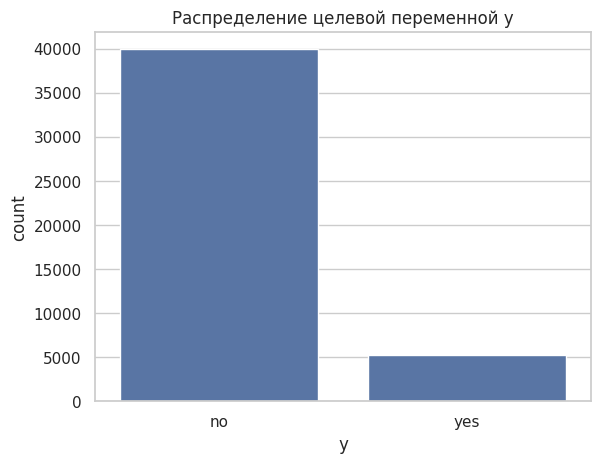

In [ ]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True).round(3))

sns.countplot(data=df, x="y")
plt.title("Распределение целевой переменной y")
plt.show()

**Интерпретация:** _впишите 1–2 предложения: что показывает график и почему это важно._

**TODO:** почему при таком дисбалансе одной accuracy недостаточно? Какую долю accuracy получит модель, которая всегда отвечает «no»?

## 4. Анализ пропусков
**Ответственный:** Алмас

В этом датасете пропуски записаны словом **"unknown"**, а не NaN. Проверим оба варианта.

In [ ]:
print("Настоящие NaN:", df.isna().sum().sum())

unknown_counts = (df == "unknown").sum()
unknown_share = (unknown_counts / len(df) * 100).round(2)
unknown_df = pd.DataFrame({"unknown_count": unknown_counts, "unknown_%": unknown_share})
unknown_df[unknown_df["unknown_count"] > 0].sort_values("unknown_count", ascending=False)

Настоящие NaN: 0


,unknown_count,unknown_%
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64


**TODO (решение и обоснование):** в каких столбцах есть «unknown» и сколько? Что вы с ними делаете (оставить как отдельную категорию, заменить на самое частое значение, что-то ещё) и **почему**? Подумайте про `poutcome`: почему там «unknown» так много?

> Подсказка: любая замена, которая считается по данным (например, «самое частое значение»), может создать утечку, если считать её до split. Отдельная категория «unknown» таких проблем не создаёт.

## 5. Числовые признаки: распределения и скошенность
**Ответственный:** Камшат

age          0.68
balance      8.36
day          0.09
duration     3.14
campaign     4.90
pdays        2.62
previous    41.85
dtype: float64


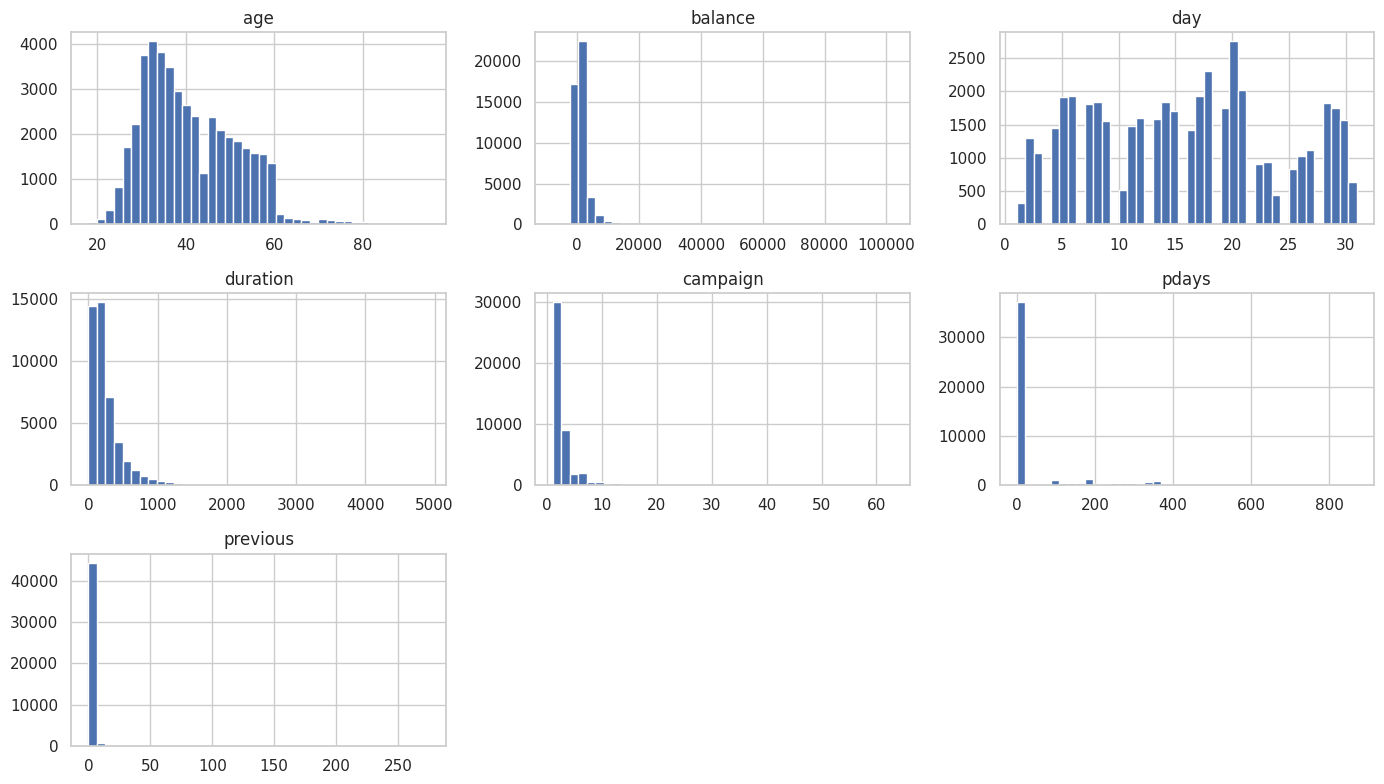

In [ ]:
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
print(df[num_cols].skew().round(2))

df[num_cols].hist(bins=40, figsize=(14, 8))
plt.show()


**Интерпретация:** Графики показывают распределение числовых характеристик клиентов; большинство из них (такие как `balance`, `duration` и `campaign`) сильно скошены вправо и содержат редкие экстремально большие значения. Понимание этого важно для выбора правильных методов предобработки, так как сильная асимметрия может негативно повлиять на качество работы чувствительных к масштабу моделей машинного обучения.

**Interpretation:** The plots illustrate the distribution of numerical client features; most of them (such as `balance`, `duration`, and `campaign`) are heavily right-skewed and contain rare extreme values. Understanding this is crucial for choosing the right preprocessing steps, as high skewness can negatively affect the performance of machine learning models sensitive to feature scales.
```


**Ответ:**
1. **Какие признаки сильно скошены:** Наиболее критическая асимметрия наблюдается у признаков `previous` (skewness ~41.85), `balance` (~8.36), `campaign` (~4.90) и `duration` (~3.14).
2. **Будем ли преобразовывать:** Да, для метрических и линейных моделей высокоскошенные признаки (особенно `balance` и `duration`) стоит преобразовать с помощью логарифмирования (например, `np.log1p` для предотвращения проблем с нулями/отрицательными значениями) или Yeo-Johnson, чтобы приблизить их распределение к нормальному и уменьшить влияние выбросов.
3. **Какие модели выигрывают:** От этого выигрывают чувствительные к масштабу и форме распределения алгоритмы: логистическая регрессия, KNN, SVM и нейронные сети. Деревья решений и построенные на них ансамбли (случайный лес, градиентный бустинг) нечувствительны к монотонным преобразованиям и масштабу, поэтому для них трансформация не критична.


## 6. Выбросы
**Ответственный:** Едиге

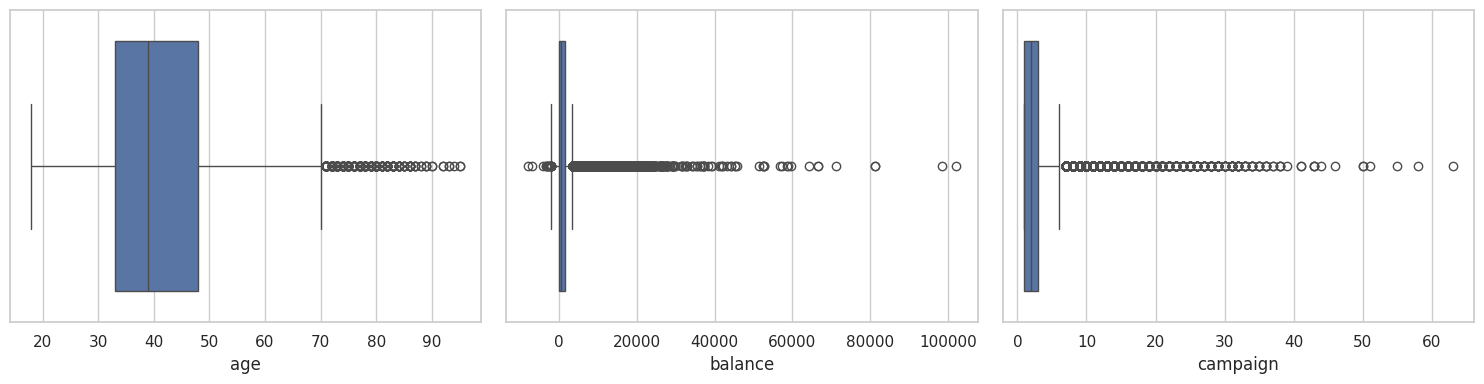

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="age", ax=axes[0])
sns.boxplot(data=df, x="balance", ax=axes[1])
sns.boxplot(data=df, x="campaign", ax=axes[2])
plt.tight_layout()
plt.show()


**Интерпретация:** Графики (boxplot) показывают наличие большого количества выбросов в признаках `balance` и `campaign`, а также умеренное количество среди возраста (`age`). Это важно, так как экстремальные значения баланса и числа контактов могут сильно сместить оценки средних значений и негативно повлиять на обучение некоторых моделей машинного обучения.




**Ответ:**
1. **Есть ли выбросы и какова их природа:** Да, выбросы присутствуют во всех трех признаках. Однако это не технические ошибки записи данных, а реальные жизненные показатели:
   - **`balance`:** Отрицательный баланс (до -8019) отражает реальную задолженность клиента (овердрафт или кредит), а экстремально высокие значения (до 102 127) соответствуют очень состоятельным клиентам.
   - **`campaign`:** Большое число контактов с одним клиентом в рамках одной кампании (до 63 звонков) также реально, хоть и говорит о неэффективном маркетинге.
   - **`age`:** Клиенты старше 70-80 лет (вплоть до 95) — это реальные пожилые люди и пенсионеры.
2. **Что мы с ними делаем и почему:** Мы **оставляем эти данные без удаления**. Удаление этих строк приведет к потере важной информации о поведении клиентов (особенно пожилых людей, которые часто открывают депозиты). Вместо удаления, для снижения негативного влияния выбросов на метрические модели, мы применим масштабирование (например, `RobustScaler`) или трансформацию признаков на этапе моделирования.


## 7. Корреляции
**Ответственный:** Алмас

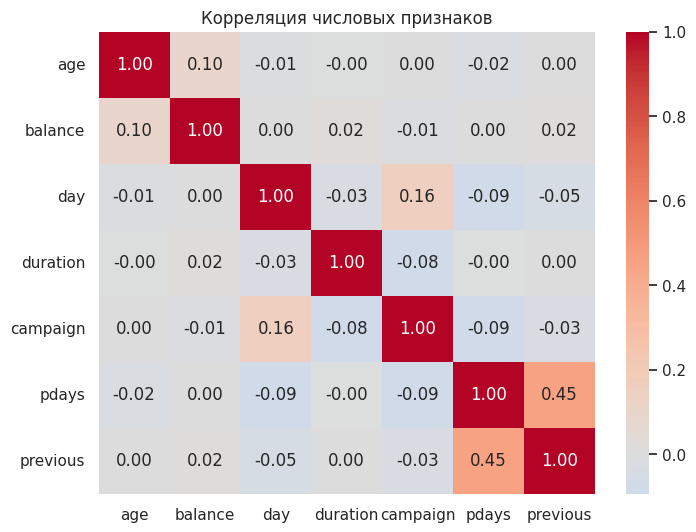

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляция числовых признаков")
plt.show()


**Интерпретация:** Тепловая карта показывает отсутствие сильной линейной взаимосвязи (коллинеарности) между большинством числовых признаков, за исключением умеренной положительной корреляции (0.45) между `pdays` и `previous`. Это важно, так как отсутствие мультиколлинеарности означает, что мы можем безопасно использовать линейные модели без риска дестабилизации их коэффициентов.



**Ответ:**
1. **Есть ли сильно связанные признаки:** Сильно связанных признаков (с корреляцией выше 0.7) на тепловой карте нет. Наиболее заметная взаимосвязь наблюдается между `pdays` (количество дней с прошлого контакта) и `previous` (количество контактов до текущей кампании) — коэффициент корреляции составляет 0.45, что вполне логично.
2. **Какие признаки окажутся информативными:** По нашему мнению, наиболее информативными для прогнозирования подписки на депозит (`y`) будут:
   - `duration` (длительность звонка): на практике это самый сильный фактор, так как долгий разговор указывает на высокий интерес клиента.
   - `poutcome` (результат предыдущей кампании): если прошлый контакт был успешным, вероятность нового согласия крайне высока.
   - `balance` (финансовая состоятельность клиента) и `housing` / `loan` (наличие кредитов): определяют наличие свободных средств для открытия депозита.


## 8. Связь категориальных признаков с целью
**Ответственный:** Камшат

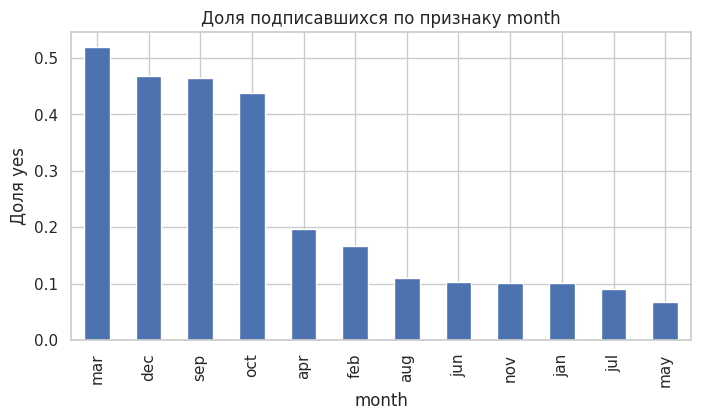

In [ ]:
df["y_bin"] = (df["y"] == "yes").astype(int)

# Строим график доли подписавшихся по месяцам напрямую
df.groupby("month")["y_bin"].mean().sort_values(ascending=False).plot(kind="bar", figsize=(8, 4))
plt.ylabel("Доля yes")
plt.title("Доля подписавшихся по признаку month")
plt.show()


**Интерпретация:** График демонстрирует, что доля успешных подписок сильно варьируется в зависимости от месяца контакта, достигая максимума в марте, сентябре, октябре и декабре. Это важно для бизнеса, так как указывает на наличие сезонности и позволяет оптимизировать распределение маркетинговых ресурсов, фокусируя кампании на наиболее конверсионных месяцах.


<Axes: title={'center': 'Доля yes по poutcome'}, ylabel='poutcome'>

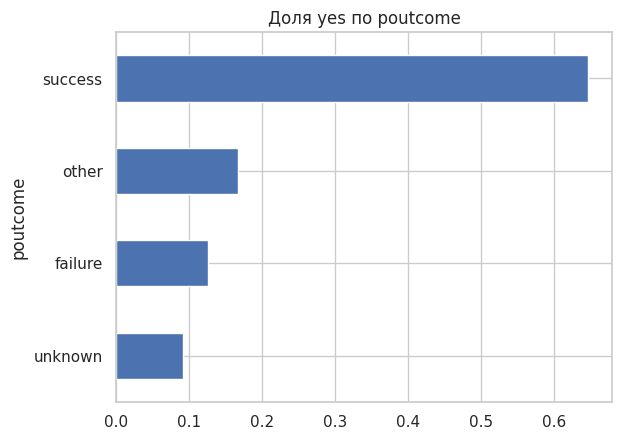

In [ ]:
df.groupby('poutcome')['y_bin'].mean().sort_values().plot(kind='barh', title='Доля yes по poutcome')


**Интерпретация:** График показывает, что клиенты с успешным исходом предыдущей кампании (`success`) демонстрируют аномально высокую долю согласий на депозит (около 65%). Это критически важно для бизнеса, так как указывает на приоритетную группу клиентов с максимальной лояльностью, на которых следует ориентировать повторные кампании.

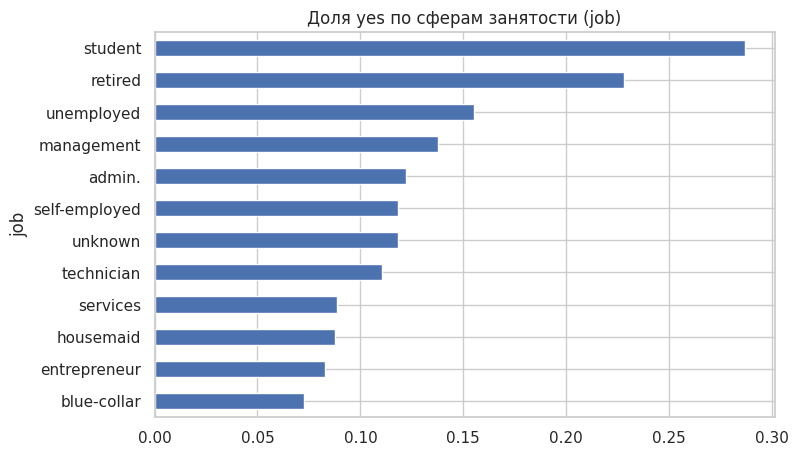

In [ ]:
df.groupby('job')['y_bin'].mean().sort_values().plot(kind='barh', figsize=(8, 5), title='Доля yes по сферам занятости (job)')
plt.show()


**Интерпретация:** График показывает, что наибольший уровень конверсии в подписку на депозит наблюдается среди студентов (`student`) и пенсионеров (`retired`), превышая 20%. Это важно для бизнеса, так как указывает на целевые сегменты с наибольшей склонностью к сбережениям, на которых стоит сфокусировать специальные предложения.

> Итого по заданию нужно **минимум 6 графиков** с интерпретациями. Сейчас у вас: дисбаланс, гистограммы, boxplot, heatmap, month, poutcome. Добавьте 1–2 для запаса.

## 9. Feature engineering и кодирование
**Ответственный:** Едиге


### Обоснование решений по Feature Engineering и кодированию:

1. **Создание признака `was_contacted_before`:** Мы создали этот бинарный признак на основе `pdays` (где значение `-1` означает отсутствие прошлых контактов). Это важно, так как сам факт наличия истории взаимодействия с клиентом сильно влияет на его текущую лояльность и вероятность согласия.
2. **Решение по признаку `duration`:** Мы приняли решение **исключить** признак `duration` (длительность звонка) на этапе финального обучения реальной модели. Обоснование: длительность звонка неизвестна до совершения самого звонка (это утечка данных из будущего/target leakage). Модель должна уметь делать прогноз *до* звонка, чтобы помочь расставить приоритеты для обзвона.
3. **Бинарные признаки (`default`, `housing`, `loan`):** Мы преобразуем текстовые значения `yes/no` в бинарный формат `1/0` для корректной математической интерпретации линейными моделями и оптимизации вычислений.
4. **Кодирование категориальных признаков:** Для мультиклассовых признаков (`job`, `marital`, `contact`, `poutcome`, `month`) мы используем One-Hot кодирование (дамми-переменные), что позволяет представить нечисловые категории в виде векторов, понятных любым алгоритмам машинного обучения.

In [ ]:
data = df.copy()

# Целевая переменная в 0/1
data["y"] = (data["y"] == "yes").astype(int)
data = data.drop(columns=["y_bin"])

# Новый признак: был ли клиент контактирован раньше
data["was_contacted_before"] = (data["pdays"] != -1).astype(int)

# Решение по duration: удаляем, чтобы предотвратить утечку данных (target leakage)
data = data.drop(columns=["duration"])

# Преобразование бинарных категориальных признаков в 0/1 без цикла
bins = ["default", "housing", "loan"]
data[bins] = (data[bins] == "yes").astype(int)

### Обоснование выбранных решений по кодированию и созданию признаков:

1. **Создание `was_contacted_before`:** Исходный признак `pdays` равен `-1` для большинства клиентов, что означает отсутствие прошлых контактов. Выделение этого факта в бинарный флаг (0 или 1) существенно упрощает улавливание этого важного сигнала линейными и метрическими моделями.
2. **Удаление `duration`:** Как детально объяснялось ранее, этот признак является классическим примером утечки данных (target leakage). Длительность звонка неизвестна до совершения звонка, поэтому использование этого признака сделало бы модель неприменимой на практике.
3. **Бинаризация (`default`, `housing`, `loan`):** Эти признаки исходно содержали только значения `yes` и `no`. Прямое преобразование в `1/0` — самый эффективный способ их представления, который сохраняет информацию и не раздувает размерность датасета.
4. **One-Hot кодирование для мультиклассовых признаков:** Переменные вроде `job`, `marital`, `education`, `contact`, `month` и `poutcome` не имеют естественного порядка (они номинальные). Использование `pd.get_dummies` с параметром `drop_first=True` позволяет закодировать эти категории без линейной зависимости между полученными столбцами, что крайне важно для линейных моделей (избегаем мультиколлинеарности).

In [ ]:
# Кодирование категориальных признаков (пример: one-hot)
# TODO: проверьте, какие столбцы остались категориальными, и закодируйте их
cat_cols = data.select_dtypes(include="object").columns.tolist()
print("Категориальные:", cat_cols)

data = pd.get_dummies(data, columns=cat_cols, drop_first=True)
data.shape

Категориальные: ['job', 'marital', 'education', 'contact', 'month', 'poutcome']


(45211, 43)

## 10. Разделение на train и test
**Ответственный:** Камшат

In [ ]:
X = data.drop(columns=["y"])
y = data["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)